In [3]:
!pip install pymorphy3 wordcloud

In [7]:
import re
import math
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt
from wordcloud import WordCloud
import pymorphy3

In [11]:
file_n="/cases_train2.xlsx"
top_n=15
min_len=3
stop_words_raw = """
и в во не что он на я с со как а то все она так его но да ты к у же вы за бы по только ее мне
было вот от меня еще нет о из ему теперь когда даже ну вдруг ли если уже или ни быть был него
до вас нибудь опять уж вам ведь там потом себя ничего ей может они тут где есть надо ней для
мы тебя их чем была сам чтоб без будто чего раз тоже себе под будет ж тогда кто этот того
потому этого какой совсем ним здесь этом один почти мой тем чтобы нее сейчас были куда зачем
всех никогда можно при наконец два об другой хоть после над больше тот через эти нас про
всего них какая много разве три эту моя впрочем хорошо свою этой перед иногда лучше чуть том
нельзя такой им более всегда конечно всю между
альфа банк банка банку банков банки клиент клиента клиентов клиенты рубль рублей рубля руб
млн млрд тыс мес миллион миллионов миллиона тысяча тысяч миллиард миллиардов год года году
лет сегмент сегмента сегменты решение решения предлагать предлагаю выбрать выбрал отрасль
являться также например около примерно целевая целевой аудитория аудитории проблема проблемы
проблем финансовая финансовый модель метрики риски риск доказательства доказательство интервью
опрос опросы партнеры партнер разработка доход доходы выручка окупаемость окупится итого чел
данные средний нужны нужно хотят барьер барьеры кейс кейса кейсе продукт вероятность высокая
средняя низкая отраслевое отраслевой собственное собственный исследование открытые открытый
ок ща крч это очень просто типа
""".split()
morph = pymorphy3.MorphAnalyzer()
stop_words ={morph.parse(w)[0].normal_form.replace("ё", "е") for w in stop_words_raw}

In [26]:
def get_words(text):
    text =str(text).lower()
    text=re.sub(r"<[^>]+>", " ",text)
    text =re.sub(r"https?://\S+", " ",text)
    text=re.sub(r"\[\d+\]", " ",text)
    words=[]
    for w in re.findall(r"[a-zа-яё]+", text):
        if len(w)>=min_len:
            lemma = morph.parse(w)[0].normal_form.replace("ё", "е")
            if lemma not in stop_words:
                words.append(lemma)
    return words

In [27]:
df=pd.read_excel(file_n)
df=df.dropna(subset=  ["Кейс", "Решение кейса"])
counters={}
for id in sorted(df["Кейс"].unique()):
    case_texts=df[df["Кейс"]== id]["Решение кейса"]
    all_words=[]
    for text in case_texts:
        all_words.extend(get_words(text))
    counters[f"Кейс {int(id)}"] = Counter(all_words)

In [28]:
n_cases=len(counters)
in_cases=Counter()
for c in counters.values():
    in_cases.update(c.keys())
tfidf_top={}
for case_name, counts in counters.items():
    total_words =sum(counts.values()) or 1
    score ={
        w: (cnt/total_words)*(math.log((1 +n_cases)/ (1 +in_cases[w]))+ 1)
        for w,cnt in counts.items() if cnt>= 2
    }
    best_words = sorted(score, key=score.get, reverse=True)[:TOP_N]
    tfidf_top[case_name] = [(w,counts[w]) for w in best_words]

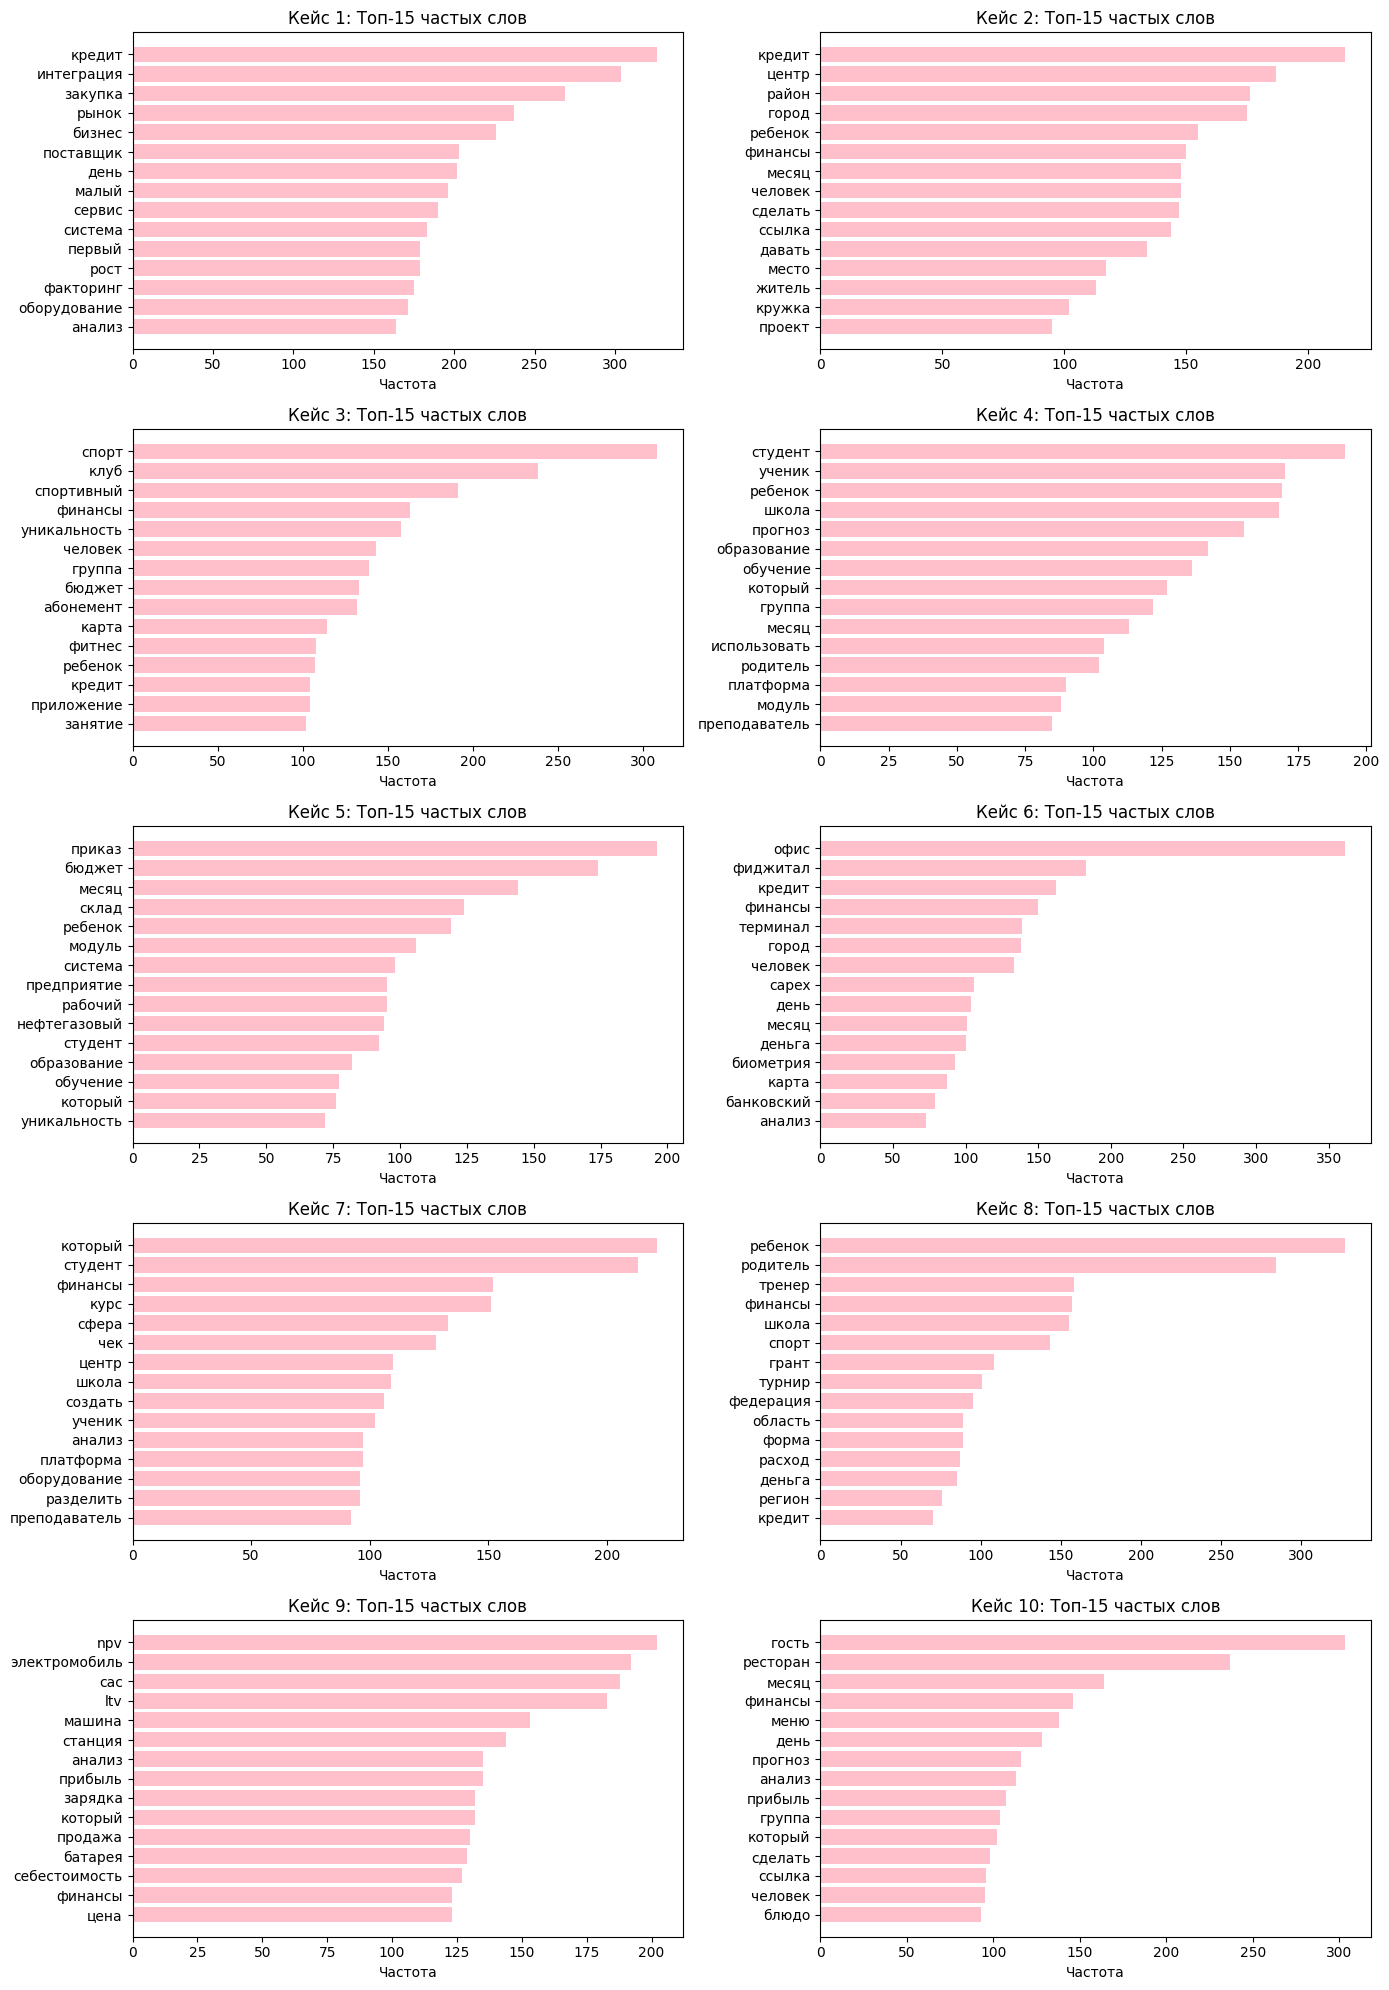

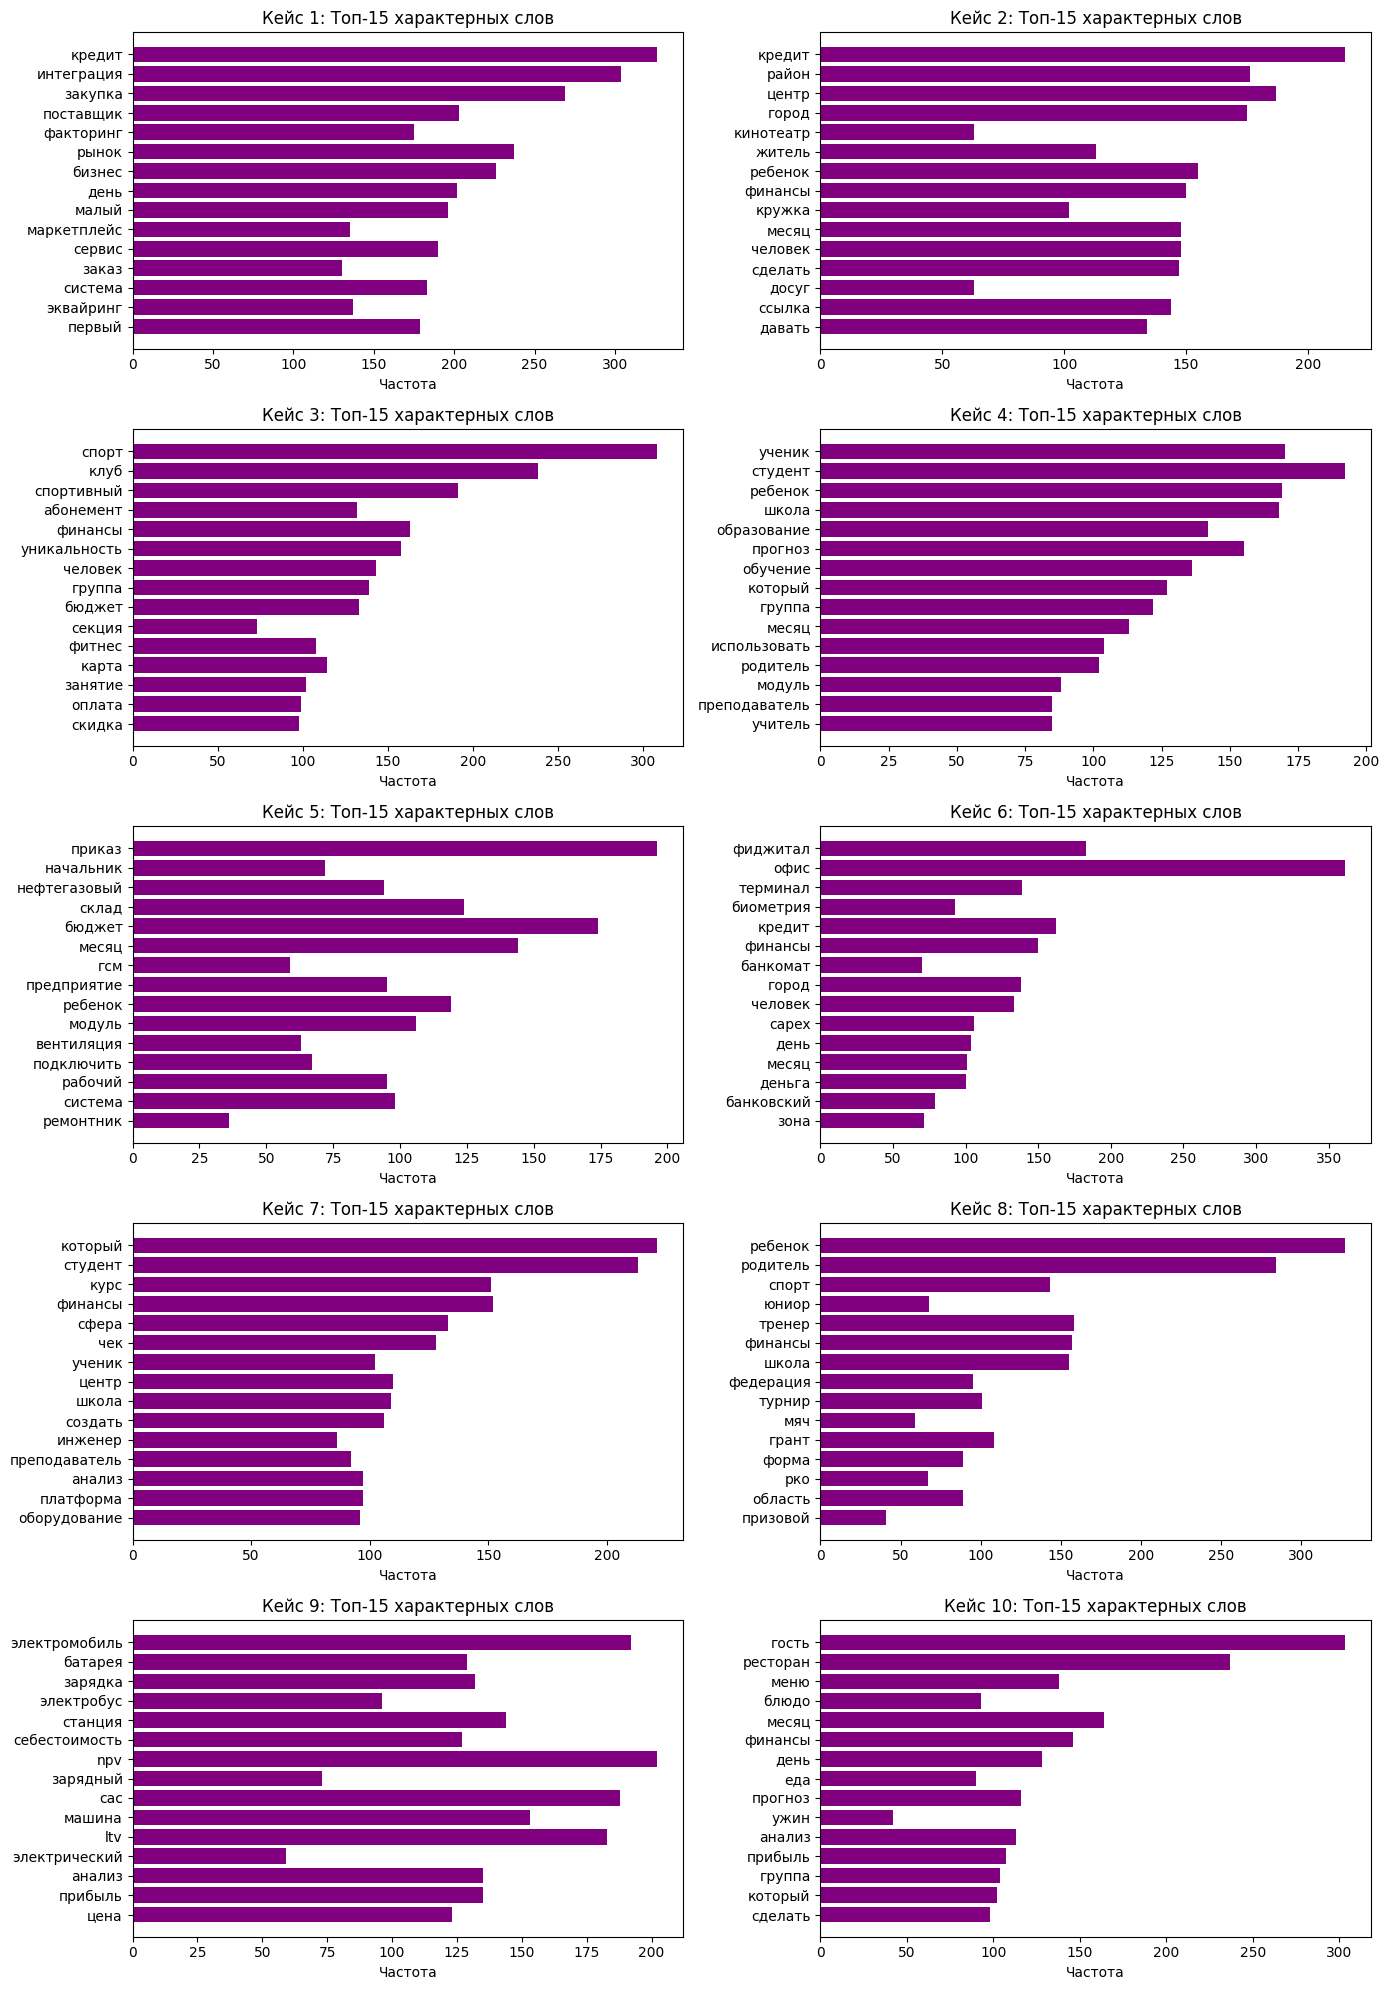

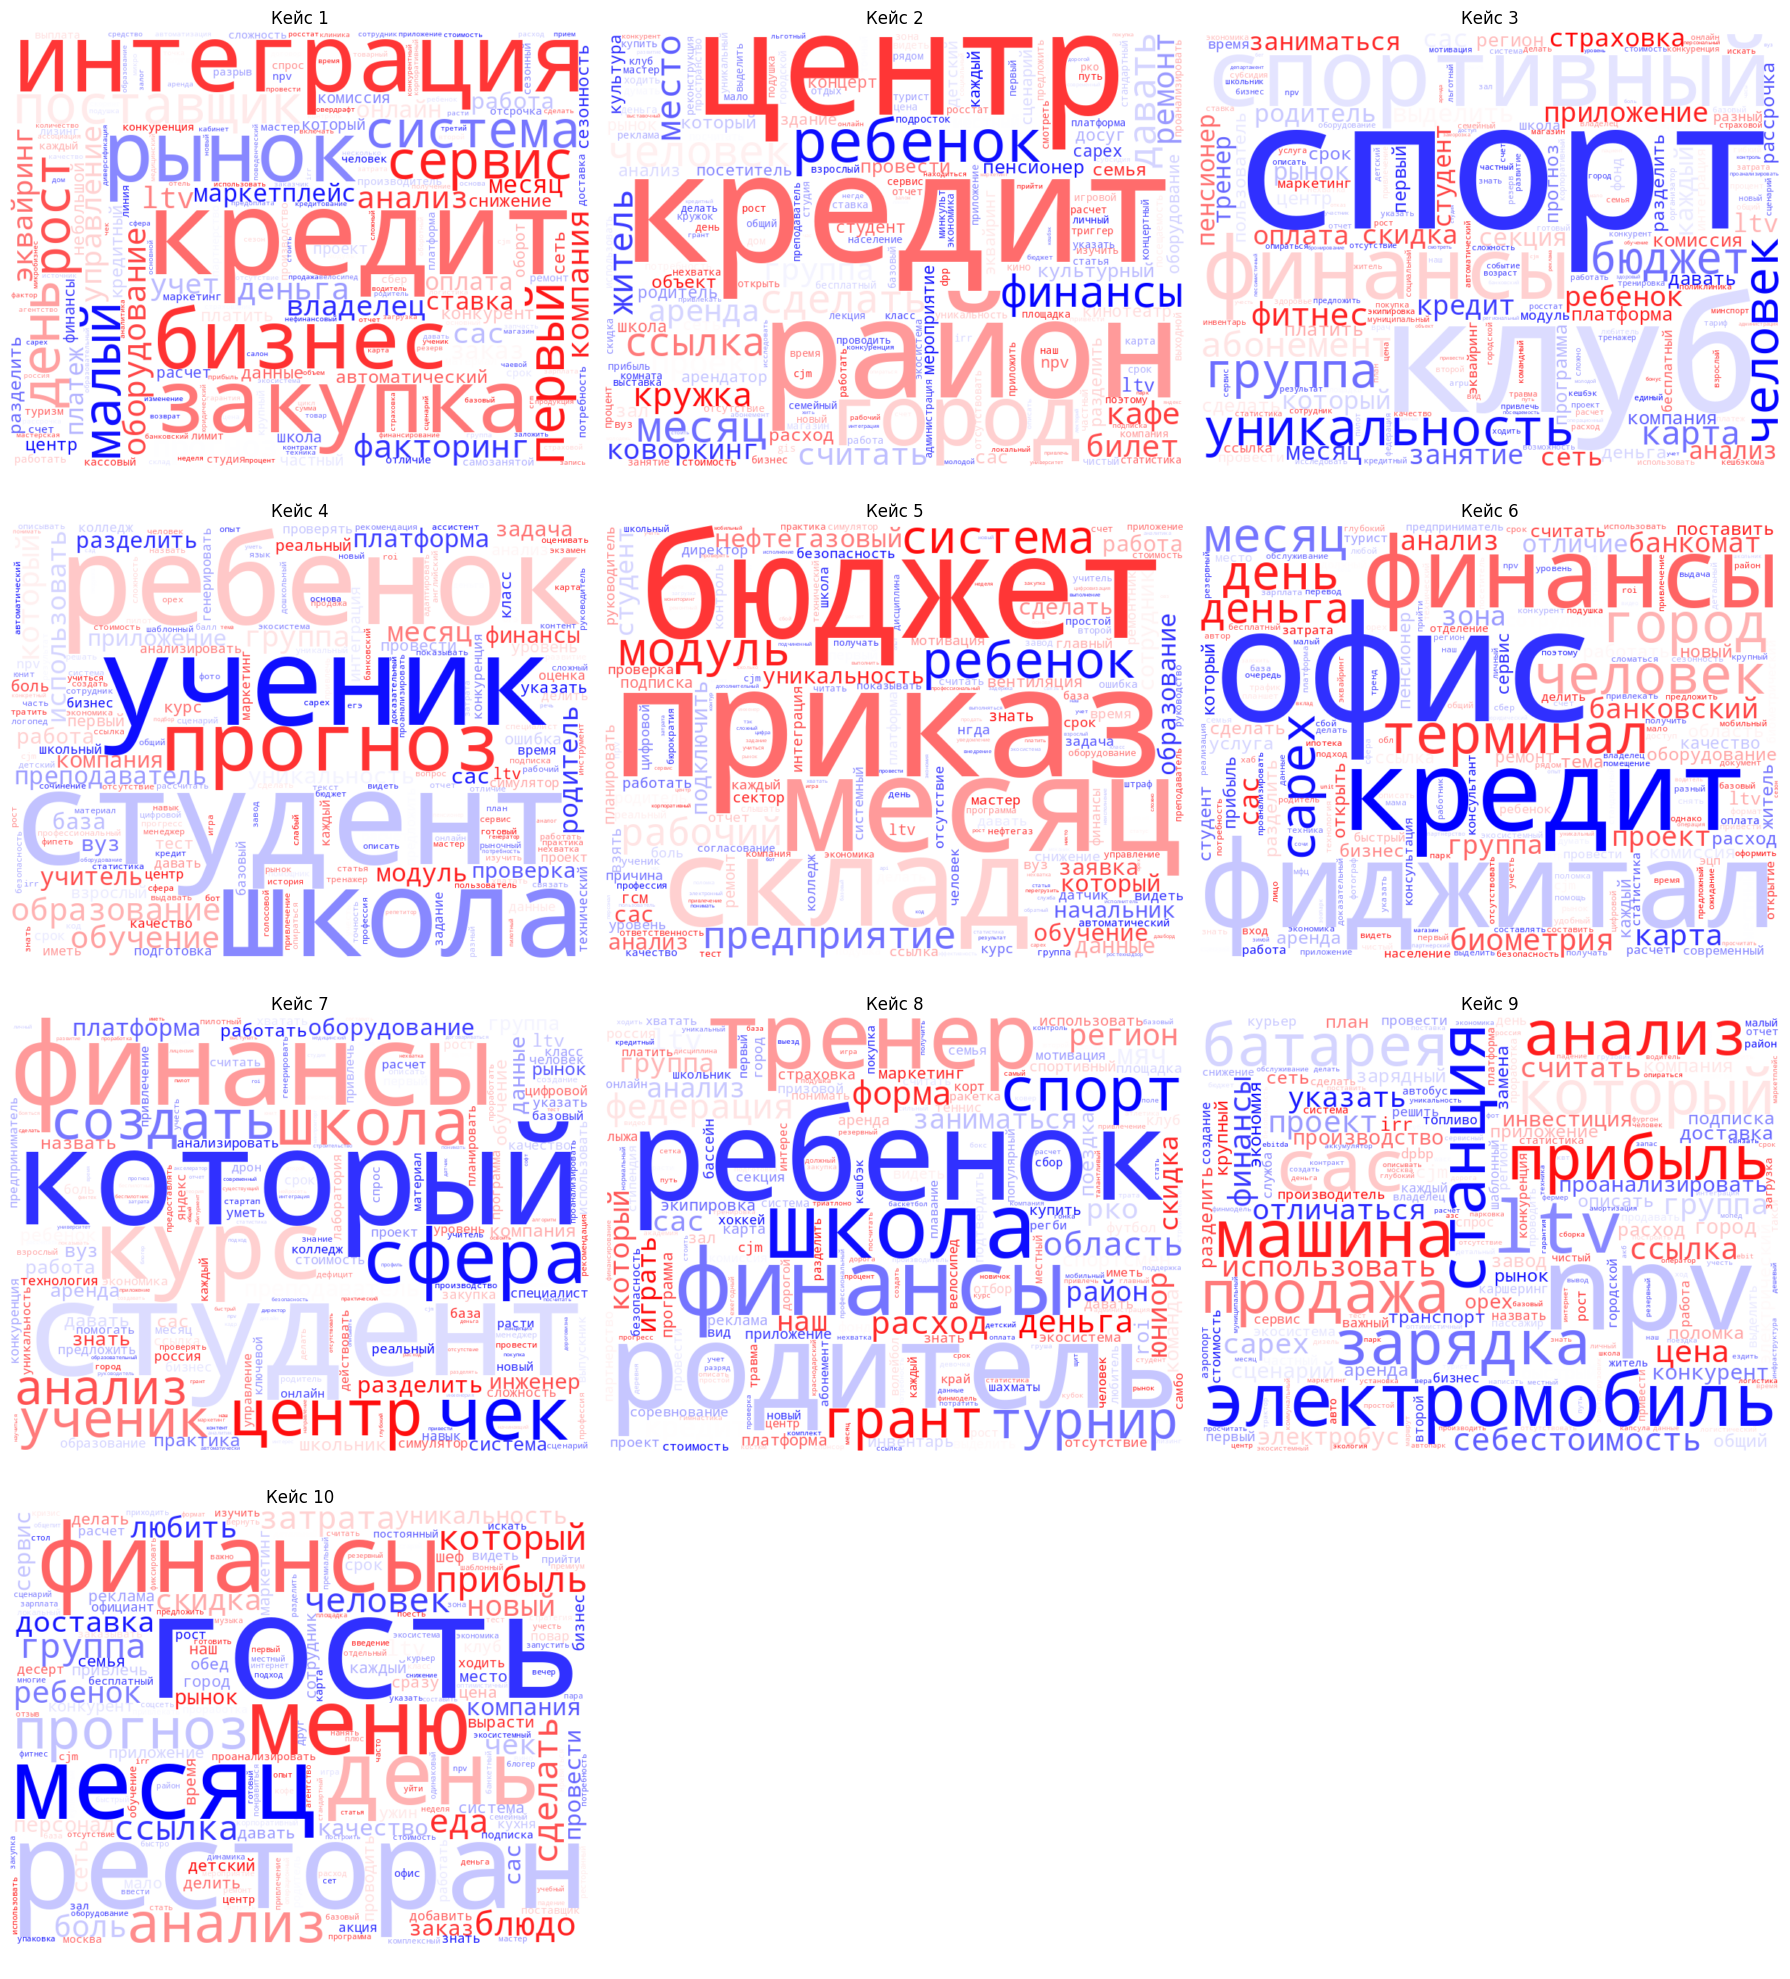

In [29]:
def plot_bars(data, title, color, filename):
    cases=list(data.keys())
    cols=2
    rows=math.ceil(len(cases)/cols)
    fig,axes =plt.subplots(rows,cols,figsize=(14,4*rows),squeeze=False)
    for ax in axes.flatten():
        ax.axis("off")
    for ax, case in zip(axes.flatten(),cases):
        ax.axis("on")
        items= data[case][::-1]
        if items:
            ax.barh([i[0] for i in items],[i[1] for i in items],color=color)
        ax.set_title(f"{case}: {title}")
        ax.set_xlabel("Частота")
    plt.tight_layout()
    plt.savefig(filename, dpi=130)
    plt.show()
    plt.close()
top_words ={case: counts.most_common(TOP_N) for case, counts in counters.items()}
plot_bars(top_words, "Топ-15 частых слов", "pink", "top_words_bars.png")
plot_bars(tfidf_top, "Топ-15 характерных слов", "purple", "distinctive_words_bars.png")
cols=3
rows=math.ceil(len(counters)/cols)
fig,axes=   plt.subplots(rows, cols, figsize=(18,5 *rows), squeeze=False)
for ax in axes.flatten():
    ax.axis("off")
for ax, (case_name, counts) in zip(axes.flatten(), counters.items()):
    if counts:
        wc = WordCloud(
            width=800, height=600, background_color="white",
            colormap="bwr", collocations=False, random_state=1
        ).generate_from_frequencies(dict(counts))
        ax.imshow(wc, interpolation="bilinear")
        ax.set_title(case_name)
plt.tight_layout()
plt.savefig("wordclouds.png", dpi=130)
plt.show()